## Step 1: Setup and State Definition


In [ ]:
# Install required packages 
%pip install -U langgraph langchain-openai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


Step 1b: Define the state

In [4]:
class ComplaintState(TypedDict):
    # Required fields
    complaint: str             # the complaint text
    category: str              # filled by intake (portal, monster, ...)
    workflow_path: List[str]   # list of stations visited, e.g. ["intake", "validate"]
    status: str                # current status, e.g. "intake", "closed", "rejected"

    # One field per station result
    is_valid: bool             # filled by validate: True or False
    reason: str                # filled by validate: why valid / not valid
    evidence: str              # filled by investigate: the lore text used
    investigation: str         # filled by investigate: the AI's findings
    resolution: str            # filled by resolve: the fix
    closure: str               # filled by close or reject: the final message

print("ComplaintState defined")

ComplaintState defined


In [5]:
initial_state = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": "",
    "workflow_path": [],
    "status": "new",
    "is_valid": False,
    "reason": "",
    "evidence": "",
    "investigation": "",
    "resolution": "",
    "closure": "",
}

print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'is_valid': False, 'reason': '', 'evidence': '', 'investigation': '', 'resolution': '', 'closure': ''}


## Step 2: Define Workflow Nodes


Step 2a: The Lore

In [6]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

Step 2b: The Intake Cell

In [10]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

Step 2c: The validate station

In [11]:
def validate_node(state: ComplaintState) -> ComplaintState:
    """Step 2: Validate - Check if the category is one we handle"""
    print("\n[VALIDATE] Checking category...")

    # Clean the category, in case the AI wrote "Portal." instead of "portal"
    category = state["category"].strip().strip(".").lower()

    if category in VALID_CATEGORIES:
        is_valid = True
        reason = f"Category '{category}' is in the valid list {VALID_CATEGORIES}."
    else:
        is_valid = False
        reason = f"Category '{category}' is not in the valid list {VALID_CATEGORIES}."

    new_state = {
        **state,
        "category": category,
        "is_valid": is_valid,
        "reason": reason,
        "workflow_path": state["workflow_path"] + ["validate"],
        "status": "validated" if is_valid else "invalid",
    }

    print(f"[VALIDATE] Valid: {is_valid} | Reason: {reason}")
    return new_state

In [12]:
# Send our starting complaint through reception and the checker
s = intake_node(initial_state)
s = validate_node(s)

print("\nPath so far:", s["workflow_path"])
print("Status:", s["status"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking category...
[VALIDATE] Valid: True | Reason: Category 'portal' is in the valid list ['portal', 'monster', 'psychic', 'environmental'].

Path so far: ['intake', 'validate']
Status: validated


In [13]:
print("Complaint:", initial_state["complaint"])

Complaint: The Downside Up portal opens at different times each day. How do I predict when?


In [14]:
test = {**initial_state, "complaint": "Demogorgons sometimes work together and sometimes fight."}
s = intake_node(test)
s = validate_node(s)


[INTAKE] Processing complaint...
[INTAKE] Categorized as: monster

[VALIDATE] Checking category...
[VALIDATE] Valid: True | Reason: Category 'monster' is in the valid list ['portal', 'monster', 'psychic', 'environmental'].


Step 2d: The investigate station

In [15]:
def investigate_node(state: ComplaintState) -> ComplaintState:
    """Step 3: Investigate - Answer the complaint using ONLY the lore"""
    print("\n[INVESTIGATE] Looking up lore...")

    category = state["category"]
    lore_text = LORE[category]          # the right chapter of the handbook

    print(f"[INVESTIGATE] Lore used ({category}): {lore_text}")

    investigation_prompt = f"""You are an investigator for NormalObjects.
Answer the complaint using ONLY the lore below.
Do not add any facts that are not in the lore.
If the lore does not answer the complaint, say: "The lore does not cover this."

LORE:
{lore_text}

COMPLAINT:
{state["complaint"]}

Answer in 2-3 sentences."""

    response = llm.invoke([HumanMessage(content=investigation_prompt)])
    investigation = response.content.strip()

    new_state = {
        **state,
        "evidence": lore_text,
        "investigation": investigation,
        "workflow_path": state["workflow_path"] + ["investigate"],
        "status": "investigated",
    }

    print(f"[INVESTIGATE] Findings: {investigation}")
    return new_state

In [16]:
s = investigate_node(s)
print("\nPath so far:", s["workflow_path"])


[INVESTIGATE] Looking up lore...
[INVESTIGATE] Lore used (monster): Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.
[INVESTIGATE] Findings: The lore indicates that Demogorgons act alone when hunting, suggesting that their behavior can vary based on circumstances. However, they do follow a hive mind when a larger entity controls them, which may explain instances of cooperation. The lore does not cover the specifics of them fighting each other.

Path so far: ['intake', 'validate', 'investigate']


Step 2e: The resolve station

In [17]:
def resolve_node(state: ComplaintState) -> ComplaintState:
    """Step 4: Resolve - Write a short fix based ONLY on the investigation"""
    print("\n[RESOLVE] Writing resolution...")

    resolution_prompt = f"""You are a resolver for NormalObjects.
Write a short, practical fix for the customer (1-2 sentences).
Use ONLY the investigation below. Do not add new facts.
If the investigation says the lore does not cover something, say that clearly.

COMPLAINT:
{state["complaint"]}

INVESTIGATION:
{state["investigation"]}"""

    response = llm.invoke([HumanMessage(content=resolution_prompt)])
    resolution = response.content.strip()

    new_state = {
        **state,
        "resolution": resolution,
        "workflow_path": state["workflow_path"] + ["resolve"],
        "status": "resolved",
    }

    print(f"[RESOLVE] Resolution: {resolution}")
    return new_state

In [18]:
test = {**initial_state, "complaint": "Demogorgons sometimes work together and sometimes fight. What's their deal?"}
print("Complaint:", test["complaint"])

s = intake_node(test)
s = validate_node(s)
s = investigate_node(s)
s = resolve_node(s)

print("\nPath so far:", s["workflow_path"])

Complaint: Demogorgons sometimes work together and sometimes fight. What's their deal?

[INTAKE] Processing complaint...
[INTAKE] Categorized as: monster

[VALIDATE] Checking category...
[VALIDATE] Valid: True | Reason: Category 'monster' is in the valid list ['portal', 'monster', 'psychic', 'environmental'].

[INVESTIGATE] Looking up lore...
[INVESTIGATE] Lore used (monster): Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.
[INVESTIGATE] Findings: Demogorgons act alone when hunting, indicating that they are typically solitary creatures. However, they can follow a hive mind when a larger entity controls them, which may explain instances where they appear to work together. The fighting among themselves could be a result of their independent nature when not under the influence of a larger force.

[RESOLVE] Writing resolution...
[RESOLVE] Resolution: Demogorgons are generally solitary creatures that hunt alone, but they can work together under

Step 2f: The close and reject stations

In [19]:
def close_node(state: ComplaintState) -> ComplaintState:
    """Step 5: Close - Confirm the complaint is done"""
    print("\n[CLOSE] Closing complaint...")

    closure = (
        f"Complaint closed. Category: {state['category']}. "
        f"Resolution: {state['resolution']}"
    )

    new_state = {
        **state,
        "closure": closure,
        "workflow_path": state["workflow_path"] + ["close"],
        "status": "closed",
    }

    print(f"[CLOSE] Status: closed")
    return new_state


def reject_node(state: ComplaintState) -> ComplaintState:
    """Reject - Stop invalid complaints and explain why"""
    print("\n[REJECT] Rejecting complaint...")

    closure = f"Complaint rejected. Reason: {state['reason']}"

    new_state = {
        **state,
        "closure": closure,
        "workflow_path": state["workflow_path"] + ["reject"],
        "status": "rejected",
    }

    print(f"[REJECT] {closure}")
    return new_state

In [20]:
s = close_node(s)
print("\nFinal path:", s["workflow_path"])
print("Status:", s["status"])


[CLOSE] Closing complaint...
[CLOSE] Status: closed

Final path: ['intake', 'validate', 'investigate', 'resolve', 'close']
Status: closed


## Step 3: Build the Graph


Step 3a: The routing function

In [21]:
def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
    """Decide where to go after validation"""
    if state["is_valid"]:
        print("[ROUTE] Valid → investigate")
        return "investigate"
    else:
        print("[ROUTE] Invalid → reject")
        return "reject"

Step 3b: Build and compile the graph

In [22]:
# 1. Create an empty graph that uses our ticket form
workflow = StateGraph(ComplaintState)

# 2. Add all the stations (nodes)
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)

# 3. Linear edges: always go from A to B
workflow.add_edge(START, "intake")          # start here
workflow.add_edge("intake", "validate")

# 4. Conditional edge: after validate, the routing function decides
workflow.add_conditional_edges(
    "validate",                 # from this station
    route_after_validation,     # ask this function
    {
        "investigate": "investigate",   # if it returns "investigate", go there
        "reject": "reject",             # if it returns "reject", go there
    },
)

# 5. More linear edges
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")

# 6. Both endings go to END
workflow.add_edge("close", END)
workflow.add_edge("reject", END)

# 7. Turn the map into a working app
app = workflow.compile()

print("Graph compiled!")

Graph compiled!


## Step 4: Test the Workflow


In [23]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")

results = []

for complaint in test_complaints:
    print("=" * 70)
    print("COMPLAINT:", complaint)

    # Fresh, empty ticket form with this complaint
    start = {**initial_state, "complaint": complaint}

    # Run the whole graph
    result = app.invoke(start)
    results.append(result)

    print("\nRESULT:")
    print("  Category:", result["category"])
    print("  Status:  ", result["status"])
    print("  Closure: ", result["closure"])

# Summary
print("=" * 70)
closed = sum(1 for r in results if r["status"] == "closed")
rejected = sum(1 for r in results if r["status"] == "rejected")
print(f"\nSUMMARY: {closed} closed, {rejected} rejected")


Testing workflow with sample complaints...

COMPLAINT: The Downside Up portal opens at different times each day. How do I predict when?

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking category...
[VALIDATE] Valid: True | Reason: Category 'portal' is in the valid list ['portal', 'monster', 'psychic', 'environmental'].
[ROUTE] Valid → investigate

[INVESTIGATE] Looking up lore...
[INVESTIGATE] Lore used (portal): Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Findings: The Downside Up portal opens when the barrier between worlds is weak, and its timing is influenced by electrical activity rather than a set schedule. Unfortunately, this means that predicting the exact times for the portal's opening can be challenging, as it does not follow a consistent daily pattern.

[RESOLVE] Writing resolution...
[RESOLVE] Resolution: The Downside Up portal opens based on fluctuating el

## Step 5: Visualize Workflow Execution


Cell 1: draw the graph

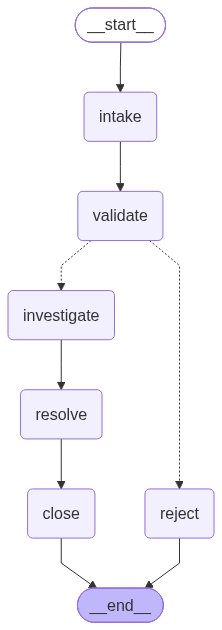

In [24]:
display(Image(app.get_graph().draw_mermaid_png()))

Cell 2: print each complaint’s path

In [25]:
for r in results:
    print(f"[{r['status'].upper()}] {' → '.join(r['workflow_path'])}")
    print(f"   {r['complaint']}\n")

[CLOSED] intake → validate → investigate → resolve → close
   The Downside Up portal opens at different times each day. How do I predict when?

[CLOSED] intake → validate → investigate → resolve → close
   Demogorgons sometimes work together and sometimes fight. What's their deal?

[CLOSED] intake → validate → investigate → resolve → close
   El can move things with her mind but can't lift heavy rocks. Why?

[CLOSED] intake → validate → investigate → resolve → close
   Why do creatures and power lines react so strangely together?

[REJECTED] intake → validate → reject
   This is not a valid complaint about something random



## Step 6: Compare with LangChain Approach



In [26]:
# 1. A valid complaint, asked directly (no graph, no lore)
print("=== VALID COMPLAINT (one LLM call) ===")
print("Complaint:", test_complaints[1])
answer = llm.invoke([HumanMessage(content=test_complaints[1])])
print(answer.content)

# 2. The invalid complaint, asked directly
print("\n=== INVALID COMPLAINT (one LLM call) ===")
print("Complaint:", test_complaints[4])
answer_invalid = llm.invoke([HumanMessage(content=test_complaints[4])])
print(answer_invalid.content)

=== VALID COMPLAINT (one LLM call) ===
Complaint: Demogorgons sometimes work together and sometimes fight. What's their deal?
Demogorgons, particularly in the context of the "Stranger Things" series, are depicted as powerful and terrifying creatures from the Upside Down. Their behavior can vary depending on the situation. 

When they work together, it often serves a strategic purpose, such as hunting for prey or defending their territory. Their cooperative behavior can enhance their effectiveness as predators, allowing them to overwhelm their targets more efficiently.

On the other hand, when they fight, it may be due to competition for resources, territory disputes, or even dominance hierarchies within their species. This conflict can also arise when they perceive a threat from other creatures or humans, leading to aggressive encounters.

Overall, their interactions can be seen as a reflection of survival instincts, where cooperation and conflict are both essential for their existence

The comparison table

| | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | Same path and category every run. Wording can change (monster: 3 runs, 3 different reasons for fighting) | No structure to keep it stable; answer depends only on the model |
| Invalid complaint rejected? | Yes: `intake → validate → reject`, with the reason | No: it answered anyway and invented a complaint about socks |
| Path visible? | Yes: `workflow_path` and log lines for every station | No: one black-box answer |
| Source of each claim? | The lore text, saved in `evidence` | Model memory ("Stranger Things", "Upside Down"); one claim contradicts the lore |
| Best for which client case? | Support/complaint processes that need rules, rejection and an audit trail | Quick brainstorming or creative answers where traceability doesn't matter |